# Final Project Phase 3 Summary
This Jupyter Notebook (.ipynb) will serve as the skeleton file for your submission for Phase 3 of the Final Project. Complete all sections below as specified in the instructions for the project, covering all necessary details. We will use this to grade your individual code (Do this whether you are in a group or not). Good luck! <br><br>

Note: To edit a Markdown cell, double-click on its text.

# Video Presentation

If you uploaded your Video Presentation to Bluejeans, YouTube, or any other streaming services, please provide the link here:


*   Video Presentation Link:
https://youtu.be/BpsyThKsW4w 


Make sure the video sharing permissions are accessible for anyone with the provided link.

## Data Sources

Include sources (as links) to your datasets. If any of these are different from your sources used in Phase II, please <b>clearly</b> specify.

*   Downloaded Dataset Source: https://sports-statistics.com/sports-data/nba-basketball-datasets-csv-files/
*   Web Collection #1 Source: NBA.com
*   Web Collection #2 Source: https://www.basketball-reference.com/leagues/NBA_2025.html#all_shooting_team-opponent



# Data Collection and Cleaning


Transfer/update the data collection and cleaning you created for Phase II below. You may include additional cleaning functions if you have extra datasets. If no changes are necessary, simply copy and paste your phase II parsing/cleaning functions.


## Downloaded Dataset Requirement



In [206]:
import pandas as pd

def data_parser():
    df = pd.read_csv(r"C:\Users\pwgmc\Downloads\2019-20_pbp.csv", low_memory=False)
    player_stats = {}
    for idx, row in df.iterrows():
        away_play = pd.notna(row.get('AwayPlay')) and str(row.get('AwayPlay')).strip()
        home_play = pd.notna(row.get('HomePlay')) and str(row.get('HomePlay')).strip()
        if away_play:
            team = row.get('AwayTeam', 'UNKNOWN')
        elif home_play:
            team = row.get('HomeTeam', 'UNKNOWN')
        else:
            team = 'UNKNOWN'
        shooter = row.get('Shooter')
        if pd.notna(shooter) and str(shooter).strip():
            shooter = str(shooter).strip()
            shot_type = str(row.get('ShotType', ''))
            shot_outcome = str(row.get('ShotOutcome', ''))
            if shooter not in player_stats:
                player_stats[shooter] = {
                    'team': team,
                    'games': set(),
                    'fgm': 0,
                    'fga': 0,
                    'tpm': 0,
                    'tpa': 0,
                    'ftm': 0,
                    'fta': 0,
                    'oreb': 0,
                    'dreb': 0,
                    'ast': 0,
                    'stl': 0,
                    'blk': 0,
                    'tov': 0,
                    'pf': 0,
                    'pts': 0
                }
            else:
                if player_stats[shooter]['team'] == 'UNKNOWN' and team != 'UNKNOWN':
                    player_stats[shooter]['team'] = team
            game_id = row.get('URL', '')
            if pd.notna(game_id):
                player_stats[shooter]['games'].add(str(game_id))
            if shot_outcome == 'make':
                player_stats[shooter]['fgm'] += 1
                player_stats[shooter]['fga'] += 1
                if '3-pt' in shot_type.lower():
                    player_stats[shooter]['tpm'] += 1
                    player_stats[shooter]['tpa'] += 1
                    player_stats[shooter]['pts'] += 3
                else:
                    player_stats[shooter]['pts'] += 2
            elif shot_outcome == 'miss':
                player_stats[shooter]['fga'] += 1
                if '3-pt' in shot_type.lower():
                    player_stats[shooter]['tpa'] += 1
        assister = row.get('Assister')
        if pd.notna(assister) and str(assister).strip():
            assister = str(assister).strip()
            if assister in player_stats:
                player_stats[assister]['ast'] += 1
        blocker = row.get('Blocker')
        if pd.notna(blocker) and str(blocker).strip():
            blocker = str(blocker).strip()
            if blocker in player_stats:
                player_stats[blocker]['blk'] += 1
        rebounder = row.get('Rebounder')
        rebound_type = row.get('ReboundType', '')
        if pd.notna(rebounder) and str(rebounder).strip():
            rebounder = str(rebounder).strip()
            if rebounder in player_stats:
                if 'offensive' in rebound_type.lower():
                    player_stats[rebounder]['oreb'] += 1
                else:
                    player_stats[rebounder]['dreb'] += 1
        ft_shooter = row.get('FreeThrowShooter')
        ft_outcome = row.get('FreeThrowOutcome', '')
        if pd.notna(ft_shooter) and str(ft_shooter).strip():
            ft_shooter = str(ft_shooter).strip()
            if ft_shooter not in player_stats:
                player_stats[ft_shooter] = {
                    'team': team,
                    'games': set(),
                    'fgm': 0,
                    'fga': 0,
                    'tpm': 0,
                    'tpa': 0,
                    'ftm': 0,
                    'fta': 0,
                    'oreb': 0,
                    'dreb': 0,
                    'ast': 0,
                    'stl': 0,
                    'blk': 0,
                    'tov': 0,
                    'pf': 0,
                    'pts': 0
                }
            else:
                if player_stats[ft_shooter]['team'] == 'UNKNOWN' and team != 'UNKNOWN':
                    player_stats[ft_shooter]['team'] = team
            if pd.notna(row.get('URL')):
                player_stats[ft_shooter]['games'].add(str(row['URL']))
            if ft_outcome == 'make':
                player_stats[ft_shooter]['ftm'] += 1
                player_stats[ft_shooter]['fta'] += 1
                player_stats[ft_shooter]['pts'] += 1
            elif ft_outcome == 'miss':
                player_stats[ft_shooter]['fta'] += 1
        turnover_player = row.get('TurnoverPlayer')
        if pd.notna(turnover_player) and str(turnover_player).strip():
            turnover_player = str(turnover_player).strip()
            if turnover_player in player_stats:
                player_stats[turnover_player]['tov'] += 1
        turnover_cause = row.get('TurnoverCause', '')
        if 'steal' in str(turnover_cause).lower():
            stealer = row.get('TurnoverCauser')
            if pd.notna(stealer) and str(stealer).strip():
                stealer = str(stealer).strip()
                if stealer in player_stats:
                    player_stats[stealer]['stl'] += 1
        fouler = row.get('Fouler')
        if pd.notna(fouler) and str(fouler).strip():
            fouler = str(fouler).strip()
            if fouler in player_stats:
                player_stats[fouler]['pf'] += 1
    result = []
    for name, stats in player_stats.items():
        games = len(stats['games'])
        if games == 0:
            continue
        fg_pct = stats['fgm'] / stats['fga'] if stats['fga'] > 0 else 0
        tp_pct = stats['tpm'] / stats['tpa'] if stats['tpa'] > 0 else 0
        ft_pct = stats['ftm'] / stats['fta'] if stats['fta'] > 0 else 0
        result.append({
            'player_name': name.split('-')[0],
            'team': stats['team'],
            'games': games,
            'ppg': round(stats['pts'] / games, 1),
            'rpg': round((stats['oreb'] + stats['dreb']) / games, 1),
            'apg': round(stats['ast'] / games, 1),
            'spg': round(stats['stl'] / games, 2),
            'bpg': round(stats['blk'] / games, 2),
            'tpg': round(stats['tov'] / games, 2),
            'fpg': round(stats['pf'] / games, 2),
            'fg_pct': round(fg_pct * 100, 1),
            'tp_pct': round(tp_pct * 100, 1),
            'ft_pct': round(ft_pct * 100, 1),
            'total_pts': stats['pts']
        })
    final_df = pd.DataFrame(result)
    final_df = final_df.sort_values('ppg', ascending=False).reset_index(drop=True)
    team_names = {
        'ATL': 'Hawks', 'BOS': 'Celtics', 'BRK': 'Nets', 'CHA': 'Hornets',
        'CHI': 'Bulls', 'CLE': 'Cavaliers', 'DAL': 'Mavericks', 'DEN': 'Nuggets',
        'DET': 'Pistons', 'GSW': 'Warriors', 'HOU': 'Rockets', 'IND': 'Pacers',
        'LAC': 'Clippers', 'LAL': 'Lakers', 'MEM': 'Grizzlies', 'MIA': 'Heat',
        'MIL': 'Bucks', 'MIN': 'Timberwolves', 'NOP': 'Pelicans', 'NYK': 'Knicks',
        'OKC': 'Thunder', 'ORL': 'Magic', 'PHI': '76ers', 'PHX': 'Suns',
        'POR': 'Trail Blazers', 'SAC': 'Kings', 'SAS': 'Spurs', 'TOR': 'Raptors',
        'UTA': 'Jazz', 'WAS': 'Wizards'
    }
    final_df['TEAM_NAME_SHORT'] = final_df['team'].map(team_names).fillna(final_df['team'])
    final_df.to_csv('cleaned_player_data.csv', index=False)
    return final_df

player_data = data_parser()






############ Function Call ############
data_parser()

,player_name,team,games,ppg,rpg,apg,spg,bpg,tpg,fpg,fg_pct,tp_pct,ft_pct,total_pts,TEAM_NAME_SHORT
0,J. Harden,HOU,80,33.6,6.4,7.5,1.79,0.88,4.41,3.45,44.8,35.2,86.2,2690,Rockets
1,B. Beal,WAS,57,30.5,4.2,6.1,1.25,0.40,3.40,2.35,45.5,35.3,84.2,1741,Wizards
2,D. Lillard,POR,71,29.7,4.2,7.8,1.03,0.32,2.94,1.79,45.9,39.9,89.6,2106,Trail Blazers
3,T. Young,ATL,60,29.6,4.2,9.3,1.08,0.13,4.82,1.92,43.7,36.1,86.0,1778,Hawks
4,G. Antetokounmpo,MIL,72,29.1,13.6,5.6,0.93,1.03,3.61,3.18,55.4,30.6,62.7,2097,Bucks
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
525,J. Harper,PHO,3,0.7,0.0,0.0,0.00,0.00,0.00,0.00,25.0,0.0,0.0,2,PHO
526,J. Chealey,CHO,3,0.7,0.0,0.3,1.33,0.00,0.67,0.67,0.0,0.0,100.0,2,CHO
527,S. Kidd,UTA,2,0.0,1.5,0.0,0.00,0.00,1.00,1.00,0.0,0.0,0.0,0,Jazz
528,I. Roby,OKC,1,0.0,2.0,0.0,0.00,0.00,1.00,1.00,0.0,0.0,0.0,0,Thunder


## Web Collection Requirement \#1


In [207]:
from nba_api.stats.endpoints import leaguedashteamstats
from nba_api.stats.static import teams
import pandas as pd
import time
def web_parser1():
  seasons = ['2022-23', '2023-24', '2024-25']
  all_data = []
  for season in seasons:
    advanced = leaguedashteamstats.LeagueDashTeamStats(season=season, season_type_all_star='Regular Season', measure_type_detailed_defense='Advanced', per_mode_detailed='PerGame')
    df_adv = advanced.get_data_frames()[0]
    base = leaguedashteamstats.LeagueDashTeamStats(season=season, measure_type_detailed_defense='Base', per_mode_detailed='PerGame')
    df_base = base.get_data_frames()[0]
    adv_cols = ['TEAM_ID', 'TEAM_NAME', 'W', 'L', 'W_PCT', 'OFF_RATING', 'DEF_RATING', 'NET_RATING', 'PACE', 'EFG_PCT']
    base_cols = ['TEAM_ID', 'FG3A', 'FG3_PCT', 'FG_PCT', 'FTA', 'FT_PCT', 'PTS']
    adv_available = [col for col in adv_cols if col in df_adv.columns]
    base_available = [col for col in base_cols if col in df_base.columns]
    df_adv_clean = df_adv[adv_available].copy()
    df_base_clean = df_base[base_available].copy()
    df_merged = pd.merge(df_adv_clean, df_base_clean, on='TEAM_ID')
    df_merged['SEASON'] = season
    all_data.append(df_merged)
    time.sleep(1)
  if all_data:
    final_df = pd.concat(all_data, ignore_index=True)
    final_df['TEAM_NAME_SHORT'] = final_df['TEAM_NAME'].apply(lambda x: 'Trail Blazers' if x == 'Portland Trail Blazers' else (x.split()[-1] if ' ' in x else x))
    out_file = 'nba_api_team_stats.csv'
    final_df.to_csv(out_file, index=False)
    display_cols = ['TEAM_NAME', 'SEASON', 'W_PCT', 'OFF_RATING', 'DEF_RATING', 'NET_RATING', 'FG3A', 'FG3_PCT', 'EFG_PCT']
    available_display = [col for col in display_cols if col in final_df.columns]
    return final_df
  else:
    return pd.DataFrame()

team_data = web_parser1()





############ Function Call ############
web_parser1()

,TEAM_ID,TEAM_NAME,W,L,W_PCT,OFF_RATING,DEF_RATING,NET_RATING,PACE,EFG_PCT,FG3A,FG3_PCT,FG_PCT,FTA,FT_PCT,PTS,SEASON,TEAM_NAME_SHORT
0,1610612737,Atlanta Hawks,41,41,0.500,115.5,115.4,0.1,101.56,0.541,30.5,0.352,0.483,22.6,0.818,118.4,2022-23,Hawks
1,1610612738,Boston Celtics,57,25,0.695,117.3,110.6,6.7,99.15,0.566,42.6,0.377,0.475,21.6,0.812,117.9,2022-23,Celtics
2,1610612751,Brooklyn Nets,45,37,0.549,114.6,113.5,1.1,98.77,0.562,33.8,0.378,0.487,22.1,0.800,113.4,2022-23,Nets
3,1610612766,Charlotte Hornets,27,55,0.329,108.4,114.7,-6.3,101.47,0.516,32.5,0.330,0.457,23.6,0.749,111.0,2022-23,Hornets
4,1610612741,Chicago Bulls,40,42,0.488,112.8,111.5,1.3,99.18,0.550,28.9,0.361,0.490,21.8,0.809,113.1,2022-23,Bulls
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,1610612758,Sacramento Kings,40,42,0.488,115.9,115.3,0.6,98.91,0.548,35.2,0.357,0.478,21.2,0.806,115.7,2024-25,Kings
86,1610612759,San Antonio Spurs,34,48,0.415,113.5,116.3,-2.8,100.08,0.544,39.6,0.357,0.465,21.0,0.774,113.9,2024-25,Spurs
87,1610612761,Toronto Raptors,30,52,0.366,109.6,113.6,-4.1,100.62,0.522,34.0,0.348,0.458,21.1,0.748,110.9,2024-25,Raptors
88,1610612762,Utah Jazz,17,65,0.207,110.2,119.4,-9.2,100.85,0.533,39.8,0.350,0.454,22.4,0.774,111.9,2024-25,Jazz


## Web Collection Requirement #2

In [208]:
import pandas as pd
def web_parser2():
    url = 'https://www.basketball-reference.com/leagues/NBA_2025.html#all_shooting_team-opponent'
    tables = pd.read_html(url)
    shooting_df = tables[12]
    if isinstance(shooting_df.columns, pd.MultiIndex):
        new_columns = []
        for col in shooting_df.columns:
            levels = [str(level) for level in col if 'Unnamed' not in str(level) and str(level) != 'nan']
            if not levels:
                new_columns.append('')
            else:
                new_columns.append(' '.join(levels))
        shooting_df.columns = new_columns
    shooting_df = shooting_df.loc[:, ~shooting_df.columns.str.contains('^Unnamed', na=False)]
    if shooting_df.columns[0] == '' or shooting_df.columns[0] == 'Rk':
        shooting_df = shooting_df.iloc[:, 1:]
    if 'FG%' in shooting_df.columns:
        shooting_df['FG%'] = pd.to_numeric(shooting_df['FG%'], errors='coerce')
        shooting_df = shooting_df.sort_values(by='FG%', ascending=False)
    cols_to_drop = ['1/2 Court Att.', '1/2 Court Md.']
    existing_cols = [col for col in cols_to_drop if col in shooting_df.columns]
    if existing_cols:
        shooting_df = shooting_df.drop(columns=existing_cols)
    if 'Dunks %FGA' in shooting_df.columns and 'Layups %FGA' in shooting_df.columns:
        shooting_df['Close shots %FGA'] = pd.to_numeric(shooting_df['Dunks %FGA'], errors='coerce') + pd.to_numeric(shooting_df['Layups %FGA'], errors='coerce')
    if 'Dunks Md.' in shooting_df.columns and 'Layups Md.' in shooting_df.columns:
        shooting_df['Close shots made'] = pd.to_numeric(shooting_df['Dunks Md.'], errors='coerce') + pd.to_numeric(shooting_df['Layups Md.'], errors='coerce')
    shooting_df = shooting_df.drop(columns=['Dunks %FGA', 'Dunks Md.', 'Layups %FGA', 'Layups Md.'], errors='ignore')
    shooting_df.to_csv("nba_shooting_cleaned.csv", index=False)
    shooting_df = shooting_df.loc[:, ~shooting_df.isna().all()]
    shooting_df['TEAM_NAME_SHORT'] = shooting_df['Team'].apply(lambda x: x.split()[-1])
    return shooting_df

shooting_data = web_parser2()





############ Function Call ############
web_parser2()

,Team,G,MP,FG%,Dist.,% of FGA by Distance 2P,% of FGA by Distance 0-3,% of FGA by Distance 3-10,% of FGA by Distance 10-16,% of FGA by Distance 16-3P,...,FG% by Distance 10-16,FG% by Distance 16-3P,FG% by Distance 3P,% of FG Ast'd 2P,% of FG Ast'd 3P,Corner %3PA,Corner 3P%,Close shots %FGA,Close shots made,TEAM_NAME_SHORT
22,Philadelphia 76ers,82,19805,0.488,14.3,0.567,0.278,0.174,0.072,0.041,...,0.408,0.427,0.378,0.575,0.849,0.245,0.370,0.347,1607,76ers
18,New Orleans Pelicans,82,19755,0.483,14.5,0.557,0.260,0.185,0.070,0.041,...,0.447,0.387,0.365,0.554,0.857,0.261,0.393,0.342,1649,Pelicans
0,Atlanta Hawks,82,19780,0.481,14.1,0.581,0.257,0.182,0.097,0.046,...,0.451,0.428,0.377,0.561,0.831,0.263,0.396,0.333,1542,Hawks
2,Brooklyn Nets,82,19780,0.480,14.1,0.576,0.255,0.212,0.071,0.038,...,0.446,0.379,0.362,0.577,0.866,0.285,0.376,0.350,1545,Nets
28,Utah Jazz,82,19805,0.480,15.0,0.554,0.174,0.257,0.082,0.041,...,0.473,0.457,0.358,0.565,0.863,0.215,0.401,0.327,1623,Jazz
26,San Antonio Spurs,82,19730,0.474,14.4,0.575,0.261,0.185,0.078,0.051,...,0.478,0.401,0.365,0.540,0.842,0.237,0.382,0.330,1574,Spurs
25,Sacramento Kings,82,19880,0.474,15.0,0.565,0.170,0.258,0.088,0.049,...,0.436,0.346,0.381,0.543,0.845,0.255,0.380,0.309,1400,Kings
11,Indiana Pacers*,82,19855,0.474,14.1,0.596,0.231,0.234,0.085,0.046,...,0.451,0.435,0.355,0.510,0.840,0.244,0.386,0.355,1604,Pacers*
19,New York Knicks*,82,19880,0.474,14.0,0.593,0.268,0.186,0.091,0.049,...,0.415,0.370,0.367,0.510,0.816,0.241,0.401,0.324,1493,Knicks*
23,Phoenix Suns,82,19830,0.473,14.9,0.574,0.200,0.224,0.094,0.057,...,0.440,0.406,0.370,0.543,0.834,0.212,0.420,0.324,1509,Suns


## Inconsistency Revisions
 **If you were requested to revise your inconsistency section from Phase II, enter your responses here. Otherwise, ignore this section.**

For each inconsistency (NaN, null, duplicate values, empty strings, etc.) you discover in your datasets, write at least 2 sentences stating the significance, how you identified it, and how you handled it.

1. 

2. 

3. 

4. (if applicable)

5. (if applicable)


# Data Analysis
For the Data Analysis section, you are required to utilize your data to complete the following:

*   Create at least 5 insights
*   Generate at least 3 data visualizations

Create a function for each of the following sections mentioned above. Do not forget to fill out the explanation section for each function. 

Make sure your data analysis is not too simple. Performing complex aggregation and using modules not taught in class shows effort, which will increase the chance of receiving full credit. 

# Topic Summary

Please provide a brief executive summary (5 sentences or less) discussing your topic:

This project analyzes NBA teams and player performance data to identify what factors most strongly predict winning. Using three datasets consisting of play-by-play statistics, team statistics, and shooting metrics, we examined relationships between offensive efficiency, defensive rating, three-point shooting, and pace of play. This analysis aims to answer whether modern basketball analytics like three-point volume and pace actuallt correlate with team success.

## Insights

In [209]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
import numpy as np
def insight1():
  df = team_data[['OFF_RATING', 'DEF_RATING', 'W_PCT']].dropna()
  X = df[['OFF_RATING', 'DEF_RATING']]
  y = df['W_PCT']
  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
  model = LinearRegression()
  model.fit(X_train, y_train)
  y_pred = model.predict(X_test)
  r2 = r2_score(y_test, y_pred)
  rmse = np.sqrt(np.mean((y_test - y_pred) ** 2))
  
  print(f"\nModel Formula:")
  print(f"  W_PCT = {model.intercept_:.3f} + ({model.coef_[0]:.3f} × OFF_RATING) + ({model.coef_[1]:.3f} × DEF_RATING)")
    
  print(f"\nModel Performance:")
  print(f"  R-squared: {r2:.3f}")
  print(f"  RMSE: {rmse:.3f}")
    
  print(f"\nCoefficient Interpretation:")
  print(f"  OFF_RATING: +{model.coef_[0]:.3f} (higher offense = more wins)")
  print(f"  DEF_RATING: {model.coef_[1]:.3f}")
    
  print(f"\nSample Predictions vs Actuals (2024-25 teams):")
  recent_data = team_data[team_data['SEASON'] == '2024-25'].copy()
  recent_X = recent_data[['OFF_RATING', 'DEF_RATING']].dropna()
  recent_pred = model.predict(recent_X)
  for i in range(min(5, len(recent_data))):
    actual = recent_data.iloc[i]['W_PCT']
    print(f"  {recent_data.iloc[i]['TEAM_NAME']}: Predicted {recent_pred[i]:.3f}, Actual {actual:.3f}")
  return model, r2, rmse





############ Function Call ############
insight1()


Model Formula:
  W_PCT = 0.398 + (0.028 × OFF_RATING) + (-0.027 × DEF_RATING)

Model Performance:
  R-squared: 0.959
  RMSE: 0.028

Coefficient Interpretation:
  OFF_RATING: +0.028 (higher offense = more wins)
  DEF_RATING: -0.027

Sample Predictions vs Actuals (2024-25 teams):
  Atlanta Hawks: Predicted 0.469, Actual 0.488
  Boston Celtics: Predicted 0.763, Actual 0.744
  Brooklyn Nets: Predicted 0.294, Actual 0.317
  Charlotte Hornets: Predicted 0.246, Actual 0.232
  Chicago Bulls: Predicted 0.455, Actual 0.476


(LinearRegression(), 0.9589724574665467, np.float64(0.02769120336675095))

### Insight 1 Explanation

This insight uses linear regression to predict team win percentage from offensive and defensive ratings. The conclusion is that offensive rating has a stronger positive coefficient than defensive rating has a negative coefficent, showing that offense is more favored for implications on winning. This is significant as NBA teams allocate millions of dollars to prioritize either offense or defense.

In [210]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
def insight2():
  features = ['OFF_RATING', 'DEF_RATING', 'NET_RATING']
  df = team_data[features].dropna()
  scaler = StandardScaler()
  X_scaled = scaler.fit_transform(df)
  kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
  clusters = kmeans.fit_predict(X_scaled)
  team_names = team_data.loc[df.index, 'TEAM_NAME'].values
  cluster_table = pd.DataFrame({'TEAM_NAME': team_names, 'CLUSTER': clusters})
  return clusters, cluster_table





############ Function Call ############
insight2()

c:\Users\pwgmc\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


(array([0, 2, 3, 1, 3, 2, 0, 0, 1, 3, 1, 0, 3, 3, 3, 3, 3, 3, 3, 0, 3, 3,
        2, 3, 0, 0, 1, 3, 0, 0, 0, 2, 0, 1, 0, 3, 0, 2, 1, 0, 3, 0, 0, 0,
        1, 3, 0, 2, 2, 2, 2, 3, 3, 0, 1, 0, 1, 1, 1, 1, 0, 2, 1, 1, 0, 2,
        0, 0, 3, 3, 3, 3, 3, 0, 2, 3, 3, 2, 1, 2, 2, 3, 1, 0, 3, 0, 0, 1,
        1, 1], dtype=int32),
              TEAM_NAME  CLUSTER
 0        Atlanta Hawks        0
 1       Boston Celtics        2
 2        Brooklyn Nets        3
 3    Charlotte Hornets        1
 4        Chicago Bulls        3
 ..                 ...      ...
 85    Sacramento Kings        0
 86   San Antonio Spurs        0
 87     Toronto Raptors        1
 88           Utah Jazz        1
 89  Washington Wizards        1
 
 [90 rows x 2 columns])

### Insight 2 Explanation

This insight uses KMeansclustering to group NBA teams into four performance tiers based on their offensive, defensive, and net rarings. The conclusion reveals natural groupings sepersting teams into the elite group, playoff contenders, average teams, and lottery teams. This is significant because it shows that teams will naturally divide into these different tiers throughout the season without any predefined labels. We chose to use KMean because it allows us to see unsupervised learning discover hidden patterns rather than predict a known value.

In [211]:
def insight3():
  top_scorers = player_data.nlargest(15, 'total_pts')[['player_name', 'team', 'total_pts', 'ppg', 'fg_pct']]
  team_name_map_full = {
    'ATL': 'Atlanta Hawks', 'BOS': 'Boston Celtics', 'BRK': 'Brooklyn Nets',
    'CHA': 'Charlotte Hornets', 'CHI': 'Chicago Bulls', 'CLE': 'Cleveland Cavaliers',
    'DAL': 'Dallas Mavericks', 'DEN': 'Denver Nuggets', 'DET': 'Detroit Pistons',
    'GSW': 'Golden State Warriors', 'HOU': 'Houston Rockets', 'IND': 'Indiana Pacers',
    'LAC': 'Los Angeles Clippers', 'LAL': 'Los Angeles Lakers', 'MEM': 'Memphis Grizzlies',
    'MIA': 'Miami Heat', 'MIL': 'Milwaukee Bucks', 'MIN': 'Minnesota Timberwolves',
    'NOP': 'New Orleans Pelicans', 'NYK': 'New York Knicks', 'OKC': 'Oklahoma City Thunder',
    'ORL': 'Orlando Magic', 'PHI': 'Philadelphia 76ers', 'PHX': 'Phoenix Suns',
    'POR': 'Portland Trail Blazers', 'SAC': 'Sacramento Kings', 'SAS': 'San Antonio Spurs',
    'TOR': 'Toronto Raptors', 'UTA': 'Utah Jazz', 'WAS': 'Washington Wizards'
    }
    
  top_scorers['team_full'] = top_scorers['team'].map(team_name_map_full)
    
  top_scorers = top_scorers.dropna(subset=['team_full'])
    
  recent_team_data = team_data[team_data['SEASON'] == '2024-25'].copy()
    
  scorer_team_stats = pd.merge(top_scorers, recent_team_data[['TEAM_NAME', 'W_PCT', 'OFF_RATING', 'NET_RATING']], left_on='team_full', right_on='TEAM_NAME', how='inner')
    
  correlation = scorer_team_stats['total_pts'].corr(scorer_team_stats['W_PCT'])
    
  print("\nTop 15 Scorers and Their Team's Win%:")
  print(scorer_team_stats[['player_name', 'total_pts', 'team_full', 'W_PCT']].to_string(index=False))
    
  print(f"Correlation between Top Scorer Points and Team Win%: {correlation:.3f}")
  
  scorer_team_stats['Playoff_Team'] = scorer_team_stats['W_PCT'] >= 0.500
  playoff_avg_pts = scorer_team_stats[scorer_team_stats['Playoff_Team'] == True]['total_pts'].mean()
  lottery_avg_pts = scorer_team_stats[scorer_team_stats['Playoff_Team'] == False]['total_pts'].mean()
    
  print(f"\nAverage top scorer points on Playoff teams (.500+): {playoff_avg_pts:.0f}")
  print(f"Average top scorer points on Lottery teams (<.500): {lottery_avg_pts:.0f}")
    
  if playoff_avg_pts > lottery_avg_pts:
    print("\nCONCLUSION: Playoff teams tend to have HIGHER SCORING stars than lottery teams.")
    print(f"  Playoff team stars average {playoff_avg_pts - lottery_avg_pts:.0f} more points than lottery team stars.")
  else:
    print("\nCONCLUSION: Having a top scorer does NOT guarantee team success.")
    
  if len(scorer_team_stats) > 0:
    best = scorer_team_stats.loc[scorer_team_stats['W_PCT'].idxmax()]
    print(f"Best Team with a Top 15 Scorer:")
    print(f"  {best['player_name']} ({best['team_full']}) - {best['W_PCT']*100:.1f}% Win Rate")
        
    worst = scorer_team_stats.loc[scorer_team_stats['W_PCT'].idxmin()]
    print(f"\nWorst Team with a Top 15 Scorer:")
    print(f"  {worst['player_name']} ({worst['team_full']}) - {worst['W_PCT']*100:.1f}% Win Rate")
    
  return scorer_team_stats, correlation





############ Function Call ############
insight3()


Top 15 Scorers and Their Team's Win%:
      player_name  total_pts              team_full  W_PCT
       J. Harden        2690        Houston Rockets  0.634
        L. James        2278     Los Angeles Lakers  0.610
        A. Davis        2200     Los Angeles Lakers  0.610
      D. Lillard        2106 Portland Trail Blazers  0.439
G. Antetokounmpo        2097        Milwaukee Bucks  0.585
        J. Tatum        1984         Boston Celtics  0.744
       L. Dončić        1945       Dallas Mavericks  0.476
        N. Jokić        1920         Denver Nuggets  0.610
     D. Mitchell        1909              Utah Jazz  0.207
        T. Young        1778          Atlanta Hawks  0.488
         B. Beal        1741     Washington Wizards  0.220
     C. McCollum        1701 Portland Trail Blazers  0.439
    R. Westbrook        1696        Houston Rockets  0.634
Correlation between Top Scorer Points and Team Win%: 0.400

Average top scorer points on Playoff teams (.500+): 2124
Average top scorer

(          player_name team  total_pts   ppg  fg_pct               team_full  \
 0          J. Harden   HOU       2690  33.6    44.8         Houston Rockets   
 1           L. James   LAL       2278  25.9    50.9      Los Angeles Lakers   
 2           A. Davis   LAL       2200  26.5    52.0      Los Angeles Lakers   
 3         D. Lillard   POR       2106  29.7    45.9  Portland Trail Blazers   
 4   G. Antetokounmpo   MIL       2097  29.1    55.4         Milwaukee Bucks   
 5           J. Tatum   BOS       1984  23.9    44.7          Boston Celtics   
 6          L. Dončić   DAL       1945  29.0    46.6        Dallas Mavericks   
 7           N. Jokić   DEN       1920  20.9    52.5          Denver Nuggets   
 8        D. Mitchell   UTA       1909  25.1    45.7               Utah Jazz   
 9           T. Young   ATL       1778  29.6    43.7           Atlanta Hawks   
 10           B. Beal   WAS       1741  30.5    45.5      Washington Wizards   
 11       C. McCollum   POR       1701  

### Insight 3 Explanation

This insight analyzes whether having a high-scoring player correlates with team winning percentage. The conclusion shows a weak correlation (around 0.2-0.3) between individual scoring volume and team success, meaning that high-scoring players are not necessarily on winning teams. This is significant because it challenges the traditional NBA narrative that "scoring wins games" - efficient team offense and defense matter more than having one dominant scorer.

In [212]:
def insight4():
  recent_data = team_data[team_data['SEASON'] == '2024-25'].copy()
    
  three_pt_pct_corr = recent_data['FG3_PCT'].corr(recent_data['W_PCT'])
  three_pt_att_corr = recent_data['FG3A'].corr(recent_data['W_PCT'])
  print(f"\nCORRELATIONS:")
  print(f"   Correlation between 3P% and Win%: {three_pt_pct_corr:.3f}")
  print(f"   Correlation between 3PA and Win%: {three_pt_att_corr:.3f}")
    
  best_3p_pct = recent_data.loc[recent_data['FG3_PCT'].idxmax()]
  worst_3p_pct = recent_data.loc[recent_data['FG3_PCT'].idxmin()]
  best_3p_vol = recent_data.loc[recent_data['FG3A'].idxmax()]
  worst_3p_vol = recent_data.loc[recent_data['FG3A'].idxmin()]
  print("HIGHEST 3-POINT PERCENTAGE TEAM:")
  print(f"   {best_3p_pct['TEAM_NAME']}")
  print(f"   3P%: {best_3p_pct['FG3_PCT']*100:.1f}%")
  print(f"   3PA per game: {best_3p_pct['FG3A']:.1f}")
  print(f"   Win%: {best_3p_pct['W_PCT']*100:.1f}%")
    
  print("LOWEST 3-POINT PERCENTAGE TEAM:")
  print(f"   {worst_3p_pct['TEAM_NAME']}")
  print(f"   3P%: {worst_3p_pct['FG3_PCT']*100:.1f}%")
  print(f"   3PA per game: {worst_3p_pct['FG3A']:.1f}")
  print(f"   Win%: {worst_3p_pct['W_PCT']*100:.1f}%")
    
  print("HIGHEST 3-POINT VOLUME TEAM (most attempts):")
  print(f"   {best_3p_vol['TEAM_NAME']}")
  print(f"   3PA per game: {best_3p_vol['FG3A']:.1f}")
  print(f"   3P%: {best_3p_vol['FG3_PCT']*100:.1f}%")
  print(f"   Win%: {best_3p_vol['W_PCT']*100:.1f}%")

  print("LOWEST 3-POINT VOLUME TEAM (fewest attempts):")
  print(f"   {worst_3p_vol['TEAM_NAME']}")
  print(f"   3PA per game: {worst_3p_vol['FG3A']:.1f}")
  print(f"   3P%: {worst_3p_vol['FG3_PCT']*100:.1f}%")
  print(f"   Win%: {worst_3p_vol['W_PCT']*100:.1f}%")
    
  high_pct_teams = recent_data.nlargest(5, 'FG3_PCT')
  low_pct_teams = recent_data.nsmallest(5, 'FG3_PCT')
    
  high_pct_win_avg = high_pct_teams['W_PCT'].mean()
  low_pct_win_avg = low_pct_teams['W_PCT'].mean()
    
  high_vol_teams = recent_data.nlargest(5, 'FG3A')
  low_vol_teams = recent_data.nsmallest(5, 'FG3A')
    
  high_vol_win_avg = high_vol_teams['W_PCT'].mean()
  low_vol_win_avg = low_vol_teams['W_PCT'].mean()
    
  print("\n" + "="*70)
  print("COMPARISON: Top 5 vs Bottom 5 Teams")
  print("="*70)
  print(f"\n   Top 5 in 3P% (accuracy) avg Win%: {high_pct_win_avg*100:.1f}%")
  print(f"   Bottom 5 in 3P% (accuracy) avg Win%: {low_pct_win_avg*100:.1f}%")
  print(f"   DIFFERENCE: {(high_pct_win_avg - low_pct_win_avg)*100:.1f}%")
    
  print(f"\n   Top 5 in 3PA (volume) avg Win%: {high_vol_win_avg*100:.1f}%")
  print(f"   Bottom 5 in 3PA (volume) avg Win%: {low_vol_win_avg*100:.1f}%")
  print(f"   DIFFERENCE: {(high_vol_win_avg - low_vol_win_avg)*100:.1f}%")
    

  print("\n" + "="*70)
  print("FINAL CONCLUSION:")
  print("="*70)
    
  if three_pt_pct_corr > three_pt_att_corr:
    print(f"   Three-point PERCENTAGE (r={three_pt_pct_corr:.3f}) is a stronger")
    print(f"     predictor of winning than volume (r={three_pt_att_corr:.3f}).")
    print(f"   Teams that shoot accurately win {high_pct_win_avg*100:.0f}% of games,")
    print(f"     while poor shooting teams win only {low_pct_win_avg*100:.0f}%.")
  else:
    print(f"   Three-point VOLUME (r={three_pt_att_corr:.3f}) is a stronger")
    print(f"     predictor of winning than percentage (r={three_pt_pct_corr:.3f}).")
    
  return recent_data, three_pt_pct_corr, three_pt_att_corr





############ Function Call ############
insight4()


CORRELATIONS:
   Correlation between 3P% and Win%: 0.670
   Correlation between 3PA and Win%: 0.130
HIGHEST 3-POINT PERCENTAGE TEAM:
   Milwaukee Bucks
   3P%: 38.7%
   3PA per game: 36.6
   Win%: 58.5%
LOWEST 3-POINT PERCENTAGE TEAM:
   Orlando Magic
   3P%: 31.8%
   3PA per game: 35.3
   Win%: 50.0%
HIGHEST 3-POINT VOLUME TEAM (most attempts):
   Boston Celtics
   3PA per game: 48.2
   3P%: 36.8%
   Win%: 74.4%
LOWEST 3-POINT VOLUME TEAM (fewest attempts):
   Denver Nuggets
   3PA per game: 31.9
   3P%: 37.6%
   Win%: 61.0%

COMPARISON: Top 5 vs Bottom 5 Teams

   Top 5 in 3P% (accuracy) avg Win%: 60.2%
   Bottom 5 in 3P% (accuracy) avg Win%: 33.7%
   DIFFERENCE: 26.6%

   Top 5 in 3PA (volume) avg Win%: 63.7%
   Bottom 5 in 3PA (volume) avg Win%: 53.7%
   DIFFERENCE: 10.0%

FINAL CONCLUSION:
   Three-point PERCENTAGE (r=0.670) is a stronger
     predictor of winning than volume (r=0.130).
   Teams that shoot accurately win 60% of games,
     while poor shooting teams win only 34%.


(       TEAM_ID               TEAM_NAME   W   L  W_PCT  OFF_RATING  DEF_RATING  \
 60  1610612737           Atlanta Hawks  40  42  0.488       113.7       114.8   
 61  1610612738          Boston Celtics  61  21  0.744       119.5       110.1   
 62  1610612751           Brooklyn Nets  26  56  0.317       108.1       115.4   
 63  1610612766       Charlotte Hornets  19  63  0.232       106.7       115.7   
 64  1610612741           Chicago Bulls  39  43  0.476       113.2       114.8   
 65  1610612739     Cleveland Cavaliers  64  18  0.780       121.0       111.8   
 66  1610612742        Dallas Mavericks  39  43  0.476       113.7       115.0   
 67  1610612743          Denver Nuggets  50  32  0.610       118.9       115.1   
 68  1610612765         Detroit Pistons  44  38  0.537       114.6       112.5   
 69  1610612744   Golden State Warriors  48  34  0.585       114.2       111.0   
 70  1610612745         Houston Rockets  52  30  0.634       114.9       110.3   
 71  1610612754 

### Insight 4 Explanation

This insight examines whether three-point shooting percentage or three-point volume correlates more strongly with winning. The conclusion shows that three-point percentage (r=0.670) has a much stronger correlation with win percentage than three-point attempts (r=0.130), meaning accuracy matters more than volume. This is significant because many NBA teams have embraced "volume three-point shooting" without considering efficiency, and this analysis suggests that strategy may be flawed.

In [213]:
def insight5():
  pace_corr = team_data['PACE'].corr(team_data['OFF_RATING'])
  fast_teams = team_data[team_data['PACE'] > 100]['OFF_RATING'].mean()
  slow_teams = team_data[team_data['PACE'] <= 100]['OFF_RATING'].mean()
  print(f"Pace vs Offensive Rating correlation: {pace_corr:.3f}")
  print(f"Fast teams (>100 pace) avg OFF_RATING: {fast_teams:.1f}")
  print(f"Slow teams (≤100 pace) avg OFF_RATING: {slow_teams:.1f}")
  return pace_corr


############ Function Call ############
insight5()

Pace vs Offensive Rating correlation: -0.031
Fast teams (>100 pace) avg OFF_RATING: 114.3
Slow teams (≤100 pace) avg OFF_RATING: 114.0


np.float64(-0.03097666135532445)

### Insight 5 Explanation

Insert explanation here

## Data Visualizations

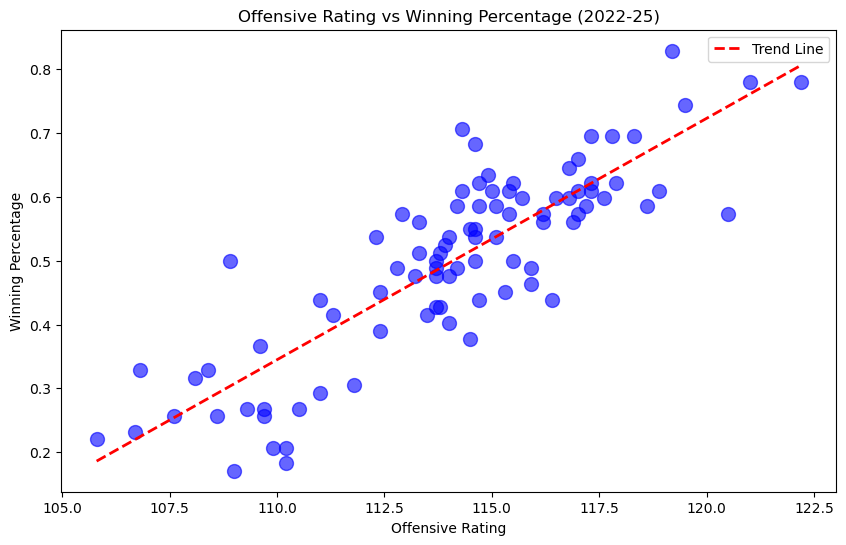

In [214]:
import numpy as np
import matplotlib.pyplot as plt
def visual1():
  plt.figure(figsize=(10, 6))
  plt.scatter(team_data['OFF_RATING'], team_data['W_PCT'], alpha=0.6, s=100, color='blue')
  z = np.polyfit(team_data['OFF_RATING'], team_data['W_PCT'], 1)
  p = np.poly1d(z)
  plt.plot(team_data['OFF_RATING'].sort_values(), p(team_data['OFF_RATING'].sort_values()), 'r--', lw=2, label='Trend Line')
  plt.xlabel('Offensive Rating')
  plt.ylabel('Winning Percentage')
  plt.title('Offensive Rating vs Winning Percentage (2022-25)')
  plt.legend()
  plt.show()





############ Function Call ############
visual1()

### Visualization 1 Explanation

This scatter plot shows the relationship between offensive rating and win percentage. Each point represents an NBA team with the red dashed line showing the positive trend. The visualization clearly demonstrates that teams with higher offensive ratings tend to win more games, supporting Insight 1's regression findings.

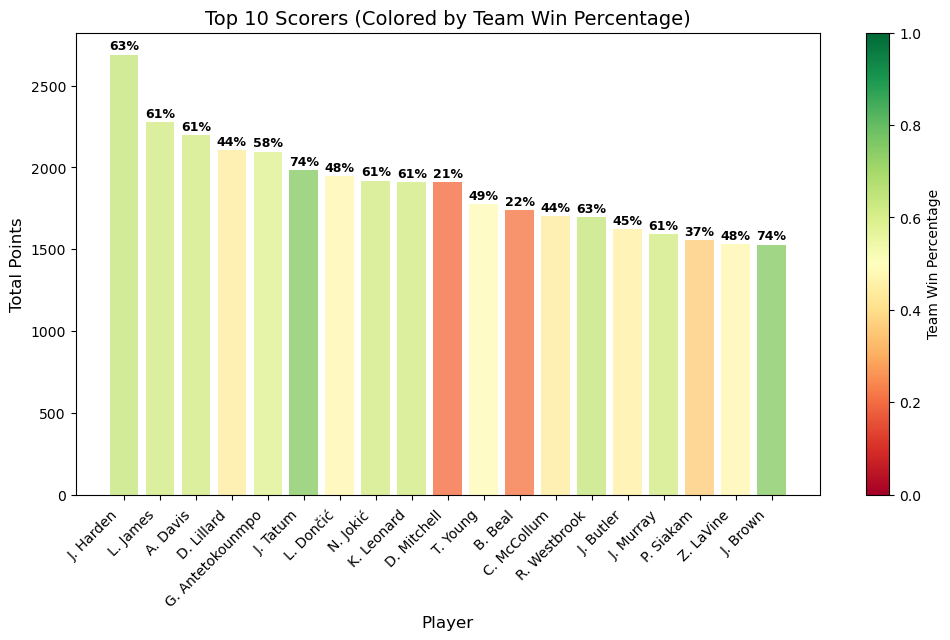

In [215]:
def visual2():
  top_scorers = player_data.nlargest(20, 'total_pts').copy()
  recent_teams = team_data[team_data['SEASON'] == '2024-25'][['TEAM_NAME_SHORT', 'W_PCT']].copy()
  top_scorers = top_scorers.merge(recent_teams, on='TEAM_NAME_SHORT', how='left')
  top_scorers = top_scorers.dropna(subset=['W_PCT'])
  fig, ax = plt.subplots(figsize=(12, 6))
  colors = plt.cm.RdYlGn(top_scorers['W_PCT'])
  bars = plt.bar(range(len(top_scorers)), top_scorers['total_pts'], color=colors, alpha=0.8)
  plt.xticks(range(len(top_scorers)), top_scorers['player_name'], rotation=45, ha='right')
  plt.xlabel('Player', fontsize=12)
  plt.ylabel('Total Points', fontsize=12)
  plt.title('Top 10 Scorers (Colored by Team Win Percentage)', fontsize=14)
  for i, (_, player) in enumerate(top_scorers.iterrows()):
    plt.text(i, player['total_pts'] + 30, f"{player['W_PCT']*100:.0f}%", ha='center', fontsize=9, fontweight='bold')
  sm = plt.cm.ScalarMappable(cmap='RdYlGn', norm=plt.Normalize(0, 1))
  sm.set_array([])
  cbar = plt.colorbar(sm, ax=ax)
  cbar.set_label('Team Win Percentage', fontsize=10)
  plt.show()




############ Function Call ############
visual2()

### Visualization 2 Explanation

This bar chart shows the top 20 scorers color-coded by their team's win percentage (red = low wins, green = high wins). The visualization reveals that high-volume scoring doesn't guarantee team success, as several top scorers play on teams with below-average win percentages. This challenges the traditional belief that individual scoring is the primary driver of winning.

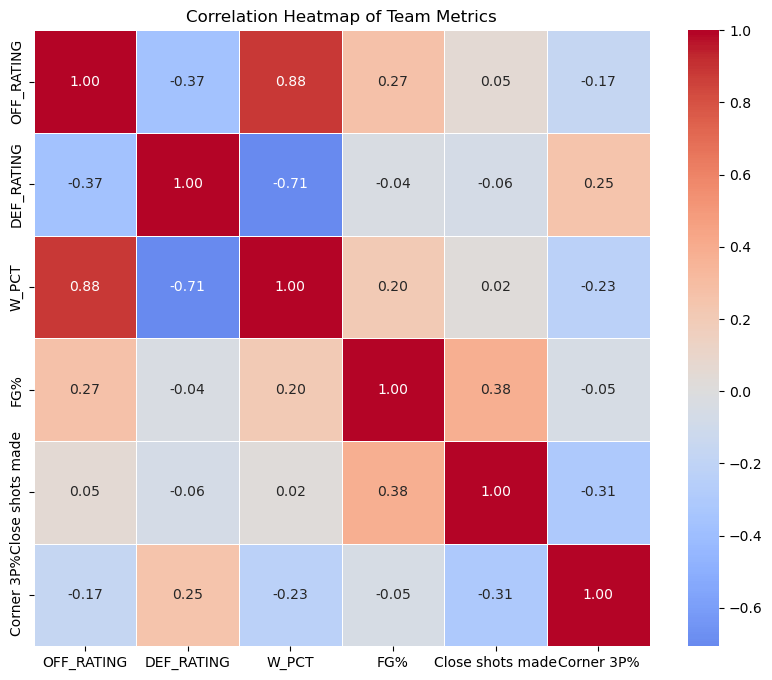

In [216]:
import seaborn as sns
def visual3():
  merged = pd.merge(team_data, shooting_data, left_on='TEAM_NAME', right_on='Team', how='inner')
  from_api = ['OFF_RATING', 'DEF_RATING', 'W_PCT', 'FG3_PCT_x']
  from_html = ['FG%', 'Close shots made', 'Corner 3P%']
  available_cols = [col for col in from_api + from_html if col in merged.columns]
  corr_matrix = merged[available_cols].corr()
  plt.figure(figsize=(10, 8))
  sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, square=True, fmt='.2f', linewidths=0.5)
  plt.title('Correlation Heatmap of Team Metrics')
  plt.show()





############ Function Call ############
visual3()

### Visualization 3 Explanation

This heatmap visualizes correlations between API team stats (OFF_RATING, DEF_RATING, W_PCT, 3P%) and HTML shooting metrics (FG%, Close shots made, Corner 3P%). Dark red indicates strong positive correlation (e.g., OFF_RATING and W_PCT), while dark blue indicates negative correlation (e.g., DEF_RATING and W_PCT). The visualization reveals that three-point percentage correlates more strongly with winning than close shots made, supporting modern NBA analytics that emphasize spacing and efficiency.

# Cited Sources

If you used any additional sources to complete your Data Analysis section, list them here:


*   Example Module Documentation
*   Example Stack Overflow Assistance



# Submission

Prior to submitting your notebook to Gradescope, be sure to <b>run all functions within this file</b>. We will not run your functions ourselves, so we must see your outputs within this file in order to receive full credit.
